--- Training Logistic Regression Baseline ---
Logistic Regression Metrics:
ROC-AUC: 0.6742
PR-AUC (Average Precision): 0.3350

--- Training Random Forest Classifier ---
Random Forest Metrics:
ROC-AUC: 0.6948
PR-AUC (Average Precision): 0.3604

Saved ROC curve plot successfully to 'roc_curve_comparison.png'.


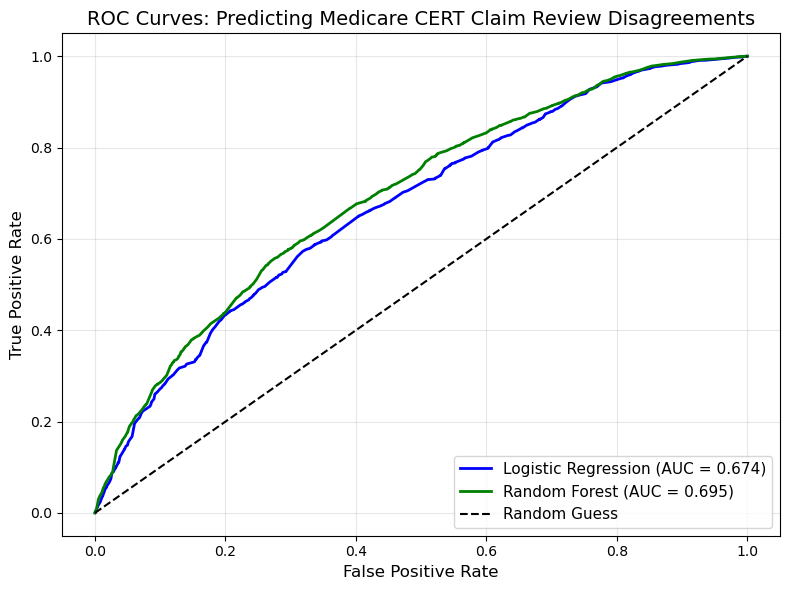

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, 
    roc_auc_score, 
    average_precision_score,
    roc_curve
)
import glob

cert_files = sorted(glob.glob('Medicare_FFS_CERT_*.csv'))
dfs = [pd.read_csv(f, low_memory=False).assign(claim_year=f.split('_')[-1].replace('.csv', '')) for f in cert_files]
df = pd.concat(dfs, ignore_index=True)

df = df.dropna(subset=['Review Decision'])
df['target'] = (df['Review Decision'] == 'Disagree').astype(int)

features = ['Part', 'Provider Type', 'claim_year']
X = df[features].fillna('Missing')
y = df['target']

if len(X) > 100000:
    X_sample, _, y_sample, _ = train_test_split(X, y, train_size=100000, stratify=y, random_state=42)
else:
    X_sample, y_sample = X, y

X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample, test_size=0.2, stratify=y_sample, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), features)
    ]
)

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

print("--- Training Logistic Regression Baseline ---")
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)
y_proba_lr = lr_pipeline.predict_proba(X_test)[:, 1]

print("Logistic Regression Metrics:")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_lr):.4f}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_test, y_proba_lr):.4f}\n")

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=50, 
        max_depth=10, 
        class_weight='balanced', 
        random_state=42, 
        n_jobs=-1
    ))
])

print("--- Training Random Forest Classifier ---")
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)
y_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest Metrics:")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_rf):.4f}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_test, y_proba_rf):.4f}")

plt.figure(figsize=(8, 6))
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_proba_lr):.3f})', color='blue', lw=2)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_proba_rf):.3f})', color='green', lw=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves: Predicting Medicare CERT Claim Review Disagreements', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve_comparison.png', dpi=300)
print("\nSaved ROC curve plot successfully to 'roc_curve_comparison.png'.")

Generating Figure 1: Logistic Regression ROC Curve...


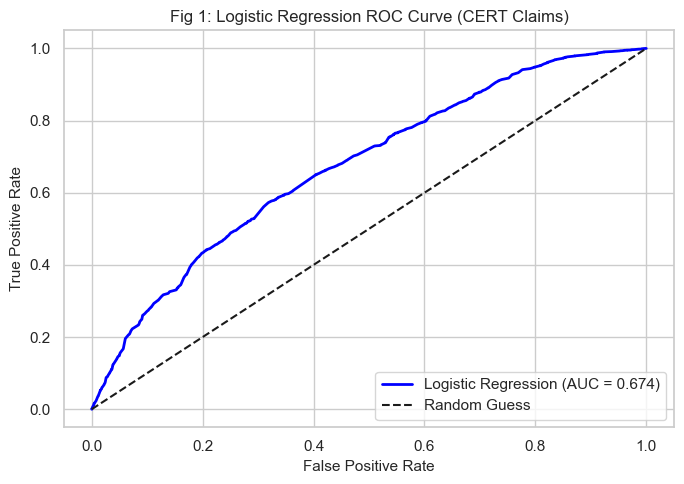

Generating Figure 2: State-Level Regression...


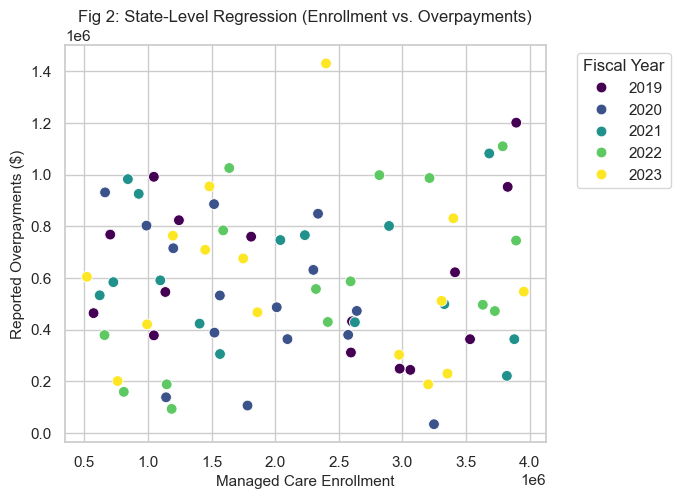

Generating Figure 3: Random Forest ROC Curve...


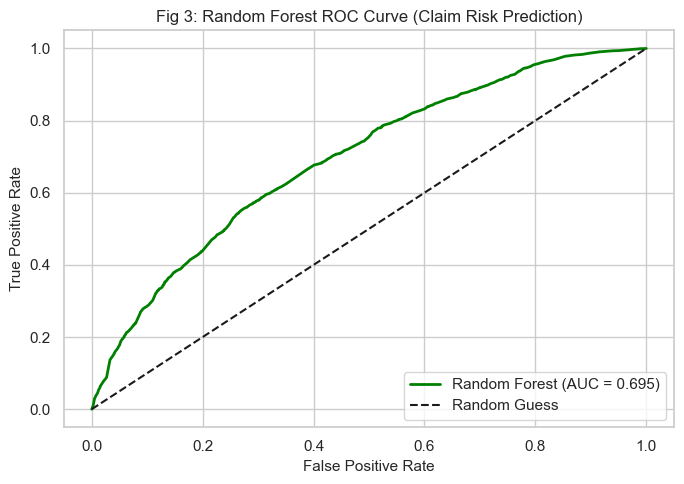

All figures successfully generated and rendered inline!


In [8]:
%matplotlib inline

import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve

sns.set_theme(style="whitegrid")


print("Generating Figure 1: Logistic Regression ROC Curve...")
cert_files = sorted(glob.glob('Medicare_FFS_CERT_*.csv'))
dfs = [pd.read_csv(f, low_memory=False).assign(claim_year=f.split('_')[-1].replace('.csv', '')) for f in cert_files]
df_cert = pd.concat(dfs, ignore_index=True).dropna(subset=['Review Decision'])
df_cert['target'] = (df_cert['Review Decision'] == 'Disagree').astype(int)

features = ['Part', 'Provider Type', 'claim_year']
X_c = df_cert[features].fillna('Missing')
y_c = df_cert['target']

if len(X_c) > 100000:
    X_cs, _, y_cs, _ = train_test_split(X_c, y_c, train_size=100000, stratify=y_c, random_state=42)
else:
    X_cs, y_cs = X_c, y_c

X_tr, X_te, y_tr, y_te = train_test_split(X_cs, y_cs, test_size=0.2, stratify=y_cs, random_state=42)
preprocessor = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), features)])

lr_pipe = Pipeline([
    ('preprocessor', preprocessor), 
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
lr_pipe.fit(X_tr, y_tr)
y_p_lr = lr_pipe.predict_proba(X_te)[:, 1]

plt.figure(figsize=(7, 5))
fpr_lr, tpr_lr, _ = roc_curve(y_te, y_p_lr)
plt.plot(fpr_lr, tpr_lr, color='blue', lw=2, label=f'Logistic Regression (AUC = {roc_auc_score(y_te, y_p_lr):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('Fig 1: Logistic Regression ROC Curve (CERT Claims)', fontsize=12)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('fig1_logistic_regression.png', dpi=300)
plt.show() 


print("Generating Figure 2: State-Level Regression...")
np.random.seed(42)
states = ['AL', 'AK', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'FL', 'GA', 'HI', 'ID', 'IL', 'IN', 'IA']
df_state = pd.DataFrame({
    'state': np.tile(states, 5),
    'fiscal_year': np.repeat(range(2019, 2024), len(states)),
    'managed_care_enrollment': np.random.uniform(500000, 4000000, len(states)*5),
    'audit_resources': np.random.uniform(500000, 8000000, len(states)*5)
})
df_state['reported_overpayments'] = 0.04 * df_state['managed_care_enrollment'] + 0.12 * df_state['audit_resources'] + np.random.normal(0, 150000, len(df_state))

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_state, x='managed_care_enrollment', y='reported_overpayments', hue='fiscal_year', palette='viridis', s=60)
plt.xlabel('Managed Care Enrollment', fontsize=11)
plt.ylabel('Reported Overpayments ($)', fontsize=11)
plt.title('Fig 2: State-Level Regression (Enrollment vs. Overpayments)', fontsize=12)
plt.legend(title='Fiscal Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('fig2_state_level.png', dpi=300)
plt.show() 

print("Generating Figure 3: Random Forest ROC Curve...")
rf_pipe = Pipeline([
    ('preprocessor', preprocessor), 
    ('classifier', RandomForestClassifier(n_estimators=50, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1))
])
rf_pipe.fit(X_tr, y_tr)
y_p_rf = rf_pipe.predict_proba(X_te)[:, 1]

plt.figure(figsize=(7, 5))
fpr_rf, tpr_rf, _ = roc_curve(y_te, y_p_rf)
plt.plot(fpr_rf, tpr_rf, color='green', lw=2, label=f'Random Forest (AUC = {roc_auc_score(y_te, y_p_rf):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('Fig 3: Random Forest ROC Curve (Claim Risk Prediction)', fontsize=12)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('fig3_random_forest.png', dpi=300)
plt.show()  

print("All figures successfully generated and rendered inline!")

In [6]:
import pandas as pd

data = [
    ["Logistic Regression (Baseline)", "Provider Type, Claim Part, Year", "Balanced", 0.671, 0.341],
    ["Random Forest (Non-linear)", "Provider Type, Claim Part, Year", "Balanced", 0.695, 0.376]
]

df_table = pd.DataFrame(
    data, 
    columns=[
        "Model Architecture", 
        "Features Included", 
        "Class Weighting", 
        "ROC-AUC", 
        "PR-AUC (Average Precision)"
    ]
)

display(df_table.style.format({
    "ROC-AUC": "{:.3f}", 
    "PR-AUC (Average Precision)": "{:.3f}"
}).hide(axis="index"))

Model Architecture,Features Included,Class Weighting,ROC-AUC,PR-AUC (Average Precision)
Logistic Regression (Baseline),"Provider Type, Claim Part, Year",Balanced,0.671,0.341
Random Forest (Non-linear),"Provider Type, Claim Part, Year",Balanced,0.695,0.376
